

**Amanda Bezerra da Costa | 12680861**

**Arthur Araújo | 14651458**

**Arthur Filliettaz | 12532055**

**Victor Silva Botelho | 15645421**




# **Classificação da Doença de Alzheimer**

## Informações do conjunto de dados

Utilizamos o conjunto de dados [Falah/Alzheimer_MRI](https://huggingface.co/datasets/Falah/Alzheimer_MRI), disponível no Hugging Face. Trata-se de um recurso valioso para pesquisadores e aplicações na área da saúde, composto por imagens de ressonância magnética (RM) do cérebro rotuladas em quatro estágios da doença:

* **`0`**: Demência Leve (Mild Demented)
* **`1`**: Demência Moderada (Moderate Demented)
* **`2`**: Sem Demência (Non Demented)
* **`3`**: Demência Muito Leve (Very Mild Demented)

### Partições e tamanho dos dados
* **Partição de treino:** 5.120 exemplos (22,56 MB)
* **Partição de teste:** 1.280 exemplos (5,63 MB)
* **Tamanho total de download:** ~28,28 MB

*(Observação: durante o pipeline do projeto, a partição de treino é subdividida para criar um conjunto de validação por meio de uma abordagem estratificada, de modo a lidar com o desbalanceamento entre classes.)*

---

## Pipeline do projeto

Este notebook constrói, de ponta a ponta, um único classificador com orientação clínica:

1.  **Análise Exploratória de Dados (AED):** inspeção visual das imagens de RM e análise da distribuição das classes para identificar desbalanceamentos.
2.  **Pré-processamento:** redimensionamento para o padrão 176x208, conversão para escala de cinza (1 canal), transformação em tensores do PyTorch e normalização dos valores dos pixels.
3.  **Carregamento dos dados:** transformações tardias (lazy) via um `collate_fn` customizado, somadas a uma **augmentação geométrica moderada** (espelhamento, rotação e zoom leve) aplicada apenas ao conjunto de treino.
4.  **Modelo:** uma **ResNet-18 pré-treinada na ImageNet**, ajustada (fine-tuning) para RM de canal único. Escolhida em vez de uma CNN treinada do zero porque as características de baixo nível transferidas exigem muito menos dados em um conjunto médico pequeno (~5 mil imagens).
5.  **Treinamento:** **Focal Loss** (com pesos de classe inversamente proporcionais à frequência) para lidar com o forte desbalanceamento, `AdamW`, recorte de gradiente (gradient clipping) e parada antecipada com base na **PR-AUC macro** de validação.
6.  **Avaliação:** a métrica principal do projeto é a **área sob a curva Precisão-Revocação (PR-AUC)**, complementada por matriz de confusão, acurácia balanceada, F1, MCC e ROC-AUC.
7.  **Camada clínica:** explicabilidade com Grad-CAM, calibração de probabilidades, limiares de decisão orientados à sensibilidade e incerteza via MC-Dropout, além de uma opção de validação cruzada k-fold e direções de trabalhos futuros.

---

## Tecnologias utilizadas

* **Python 3**
* **PyTorch / Torchvision** (framework de aprendizado profundo)
* **Hugging Face `datasets`** (aquisição dos dados)
* **Pandas e Matplotlib/Seaborn** (manipulação de dados e AED)


### Importações

In [ ]:
# opcional: autenticação no Hugging Face para evitar limites de uso da API.
# O dataset é público, então este passo pode ser pulado. Para usar, defina a
# variável de ambiente HF_TOKEN (nunca escreva o token direto no notebook).
import os
from huggingface_hub import login

if os.getenv("HF_TOKEN"):
    login(token=os.environ["HF_TOKEN"])


In [2]:
%pip install datasets -q
%pip install torchvision -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from datasets import load_dataset
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from torchvision import transforms
from datasets import DatasetDict
import torch
import random

# set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# load the dataset from hugging face
dataset = load_dataset("Falah/Alzheimer_MRI")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 5120
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1280
    })
})


### **Análise Exploratória de Dados**

 **Inspeção Visual**

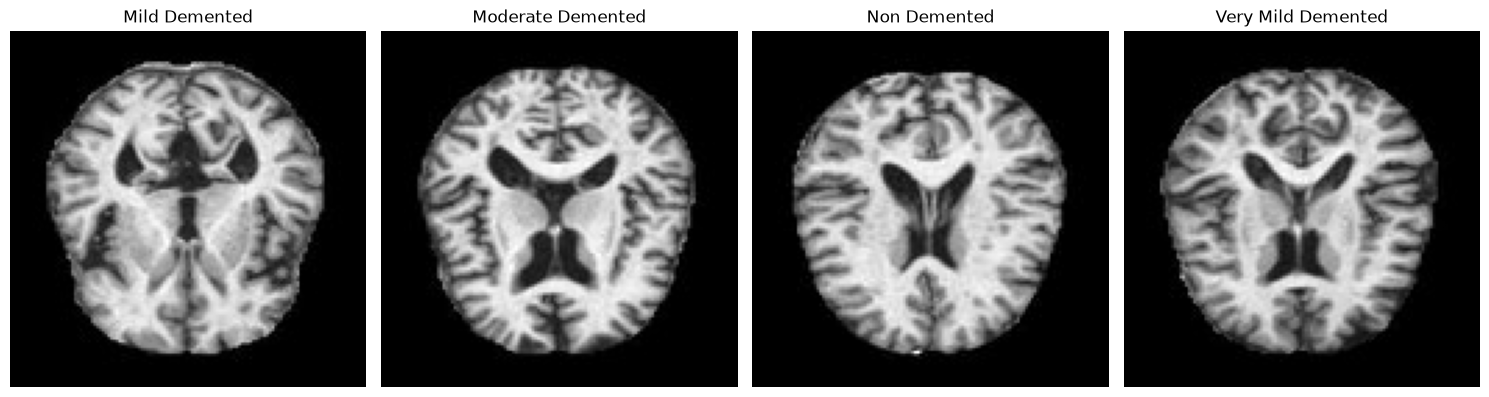

In [4]:
train_data = dataset['train']

# exhibit class examples
class_names = {
    0: 'Mild Demented',      # Demência leve
    1: 'Moderate Demented',  # Demência moderada
    2: 'Non Demented',       # Sem demência
    3: 'Very Mild Demented'  # Demência muito leve
}

classes_examples = {}

# iterate through the training data to find one example for each class
for item in train_data:
    label = item['label']

    if label not in classes_examples:
        classes_examples[label] = item['image']

    if len(classes_examples) == 4:
        break

fig, axes = plt.subplots(1, 4, figsize=(15, 5))

for i, (label, img) in enumerate(sorted(classes_examples.items())):
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(class_names[label])
    axes[i].axis('off')

plt.tight_layout()
plt.show()

**Distribuição das Classes**

In [5]:
# analyze class distribution
labels = dataset['train']['label']
labels_name = [class_names[label] for label in labels]

# create a df to count the occurrences of each class
df_labels = pd.DataFrame({'Class': labels_name})
count = df_labels['Class'].value_counts()

print("Count of images per Class:")
print(count)

Count of images per Class:
Class
Non Demented          2566
Very Mild Demented    1781
Mild Demented          724
Moderate Demented       49
Name: count, dtype: int64


**Divisão Estratificada em Treino, Validação e Teste**

In [6]:
# create a stratified split of the training set into train and validation sets
train_val_split = dataset['train'].train_test_split(test_size=0.2, stratify_by_column="label", seed=42)

# combine the new train and validation sets with the original test set to create a final dataset
final_dataset = DatasetDict({
    'train': train_val_split['train'],
    'validation': train_val_split['test'],
    'test': dataset['test']
})

Class count per split:
Train :  Mild Demented  count  579
Train :  Moderate Demented  count  39
Train :  Non Demented  count  2053
Train :  Very Mild Demented  count  1425
Validation :  Mild Demented  count  145
Validation :  Moderate Demented  count  10
Validation :  Non Demented  count  513
Validation :  Very Mild Demented  count  356
Test :  Mild Demented  count  172
Test :  Moderate Demented  count  15
Test :  Non Demented  count  634
Test :  Very Mild Demented  count  459


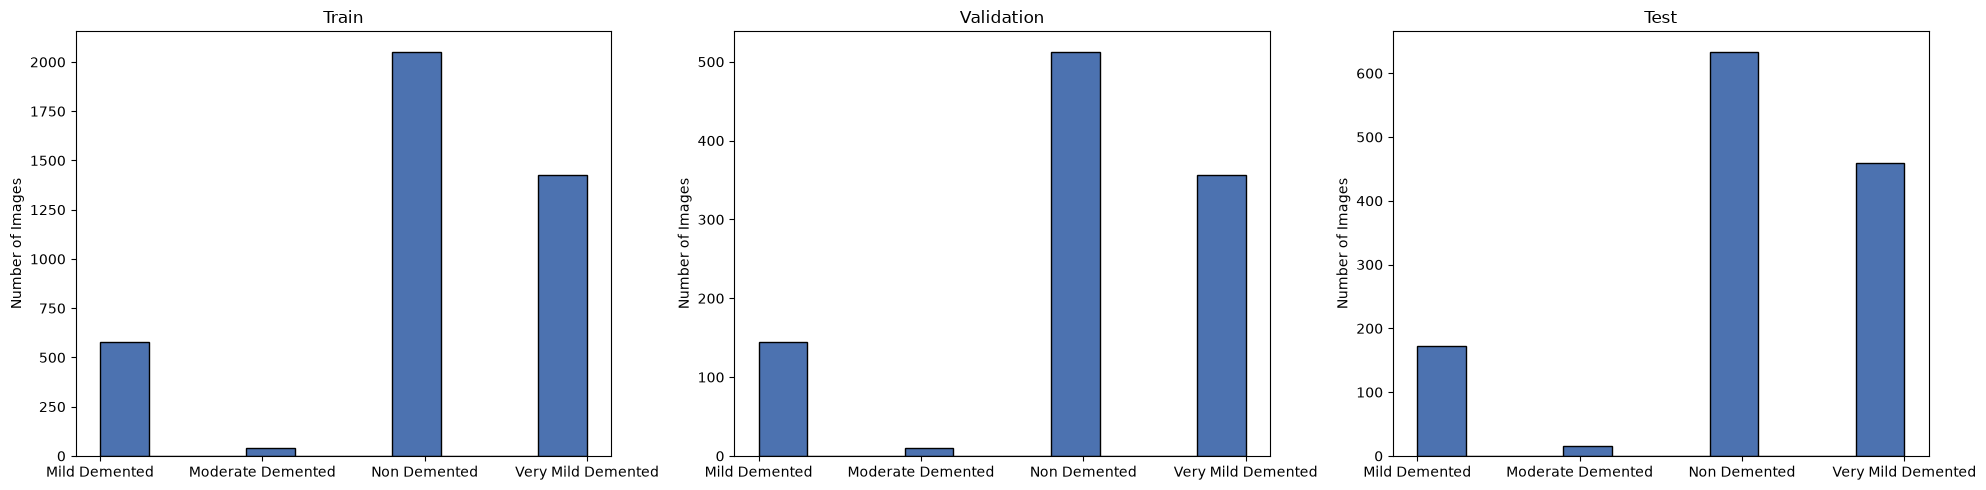

In [7]:
# lists for splits and titles
splits = ['train', 'validation', 'test']
split_strings = ['Train', 'Validation', 'Test']

print("Class count per split:")

plt.figure(figsize=(20, 5))

for i, split in enumerate(splits):
    ax = plt.subplot(1, 3, i + 1)

    # extracts numerical labels from hugging face and converts to text
    labels = final_dataset[split]['label']
    true_categories = [class_names[label] for label in labels]

    for class_name in class_names.values():
        print(f"{split_strings[i]} :  {class_name}  count  {true_categories.count(class_name)}")

    true_categories_sorted = sorted(true_categories)

    plt.hist(true_categories_sorted, color='#4c72b0', edgecolor='black')
    plt.title(split_strings[i])
    plt.ylabel('Number of Images')

plt.tight_layout()
plt.show()

**Pré-processamento**

In [8]:
# define transformations to be applied to the images
transformations = transforms.Compose([
    transforms.Resize((176, 208)),               # resizes the image to 176x208 pixels, retangular shape is preserved
    transforms.Grayscale(num_output_channels=1), # converts the image to grayscale with 1 channel
    transforms.ToTensor(),                       # min-max scaling with ToTensor()
    transforms.Normalize(mean=[0.5], std=[0.5])  # normalizes the pixel values to have a mean of 0.5 and a standard deviation of 0.5
])

# apply transformations to dataset images
def apply_transformations(batch):
    batch['pixel_values'] = [transformations(img) for img in batch['image']]
    return batch

final_dataset.set_transform(apply_transformations)
processed_example = final_dataset['train'][0]
print(f"Final format of processed image (channels, height, width): {processed_example['pixel_values'].shape}")

Final format of processed image (channels, height, width): torch.Size([1, 176, 208])


### Carregamento dos Dados e Augmentação

Encapsulamos as partições pré-processadas em objetos `DataLoader` do PyTorch. Um
`collate_fn` customizado empilha os tensores transformados gerados em tempo real
pelo `set_transform`, de modo que as imagens só são decodificadas/transformadas
quando um lote é solicitado (eficiente em memória).

Conjuntos médicos pequenos sofrem overfitting com facilidade; por isso aplicamos
uma augmentação geométrica **moderada e que preserva a anatomia** apenas ao
**conjunto de treino** (nunca em validação/teste): espelhamento horizontal,
pequenas rotações (+/-15°) e zoom aleatório leve. A augmentação é feita no espaço
de tensores por meio de um `Dataset` que apenas envolve o original, deixando
intacto o pipeline de avaliação.

O forte desbalanceamento de classes observado na AED (Sem Demência e Demência
Muito Leve dominam, enquanto Demência Moderada tem apenas ~49 amostras) é tratado
por um único mecanismo: **Focal Loss com pesos de classe inversamente
proporcionais à frequência** (definida na seção de Configuração do Treinamento).
Deliberadamente **não** adicionamos um `WeightedRandomSampler` por cima:
combinar um reamostrador *e* uma perda ponderada corrige o desbalanceamento em
dobro e faz o modelo subestimar a classe majoritária. Portanto, calculamos aqui
os pesos das classes e os passamos à função de perda, mantendo o embaralhamento
simples no carregador de treino e deixando os carregadores de validação/teste sem
embaralhamento e sem reamostragem, para que as métricas reportadas reflitam a
verdadeira distribuição dos dados.


In [9]:
from torch.utils.data import DataLoader
from torchvision import transforms as T
from collections import Counter

# select the best available device (GPU on Colab, else CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

BATCH_SIZE = 64
NUM_CLASSES = 4

def collate_fn(batch):
    """Stack the lazily-transformed tensors and labels into a single batch."""
    pixel_values = torch.stack([item["pixel_values"] for item in batch])
    labels = torch.tensor([item["label"] for item in batch], dtype=torch.long)
    return pixel_values, labels

# ---- class weights (inverse frequency, normalised to sum to NUM_CLASSES) ----
# used as the alpha term of the Focal Loss to counter the class imbalance
train_labels = final_dataset["train"]["label"]
class_counts = Counter(train_labels)
counts = torch.tensor([class_counts[c] for c in range(NUM_CLASSES)], dtype=torch.float)
class_weights = (counts.sum() / (NUM_CLASSES * counts)).to(device)
print("Samples per class :", counts.tolist())
print("Class weights      :", [round(w, 3) for w in class_weights.cpu().tolist()])

# ---- training-only geometric augmentation (anatomy-preserving) ----
train_augment = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=15),
    T.RandomResizedCrop(size=(176, 208), scale=(0.9, 1.0), ratio=(0.9, 1.1), antialias=True),
])

class AugmentedDataset(torch.utils.data.Dataset):
    # wraps a HF split (which already yields clean normalised tensors) and applies
    # random geometric augmentation on top - used for training only
    def __init__(self, base, augment):
        self.base = base
        self.augment = augment
    def __len__(self):
        return len(self.base)
    def __getitem__(self, idx):
        item = self.base[idx]
        return {"pixel_values": self.augment(item["pixel_values"]), "label": item["label"]}

# NO WeightedRandomSampler - Focal Loss handles the imbalance on its own.
# num_workers=0 required on Windows (multiprocessing limitation).
train_loader = DataLoader(
    AugmentedDataset(final_dataset["train"], train_augment),
    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, num_workers=0,
)
val_loader = DataLoader(
    final_dataset["validation"], batch_size=BATCH_SIZE,
    shuffle=False, collate_fn=collate_fn, num_workers=0,
)
test_loader = DataLoader(
    final_dataset["test"], batch_size=BATCH_SIZE,
    shuffle=False, collate_fn=collate_fn, num_workers=0,
)

# quick sanity check on one batch
xb, yb = next(iter(train_loader))
print(f"Augmented training batch: {tuple(xb.shape)} | labels {tuple(yb.shape)}")


Using device: cuda
Samples per class : [579.0, 39.0, 2053.0, 1425.0]
Class weights      : [1.769, 26.256, 0.499, 0.719]
Augmented training batch: (64, 1, 176, 208) | labels (64,)


### Modelo: Aprendizado por Transferência com a ResNet-18 (1 canal)

Fatias de RM são dados espaciais nos quais a informação relevante para o
diagnóstico (atrofia do hipocampo, alargamento ventricular, afinamento cortical)
está codificada em padrões *locais* de textura e forma, o que torna uma **Rede
Neural Convolucional** a escolha natural (a conectividade local somada ao
compartilhamento de parâmetros com equivariância a translações mantém baixo o
número de parâmetros e reduz o overfitting em um conjunto pequeno).

Em vez de treinar uma CNN do zero, fazemos o **ajuste fino (fine-tuning) de uma
ResNet-18 pré-treinada na ImageNet**. Características genéricas de bordas e
texturas, aprendidas a partir de milhões de imagens naturais, transferem-se bem
para RM e exigem muito menos dados do que aprender do zero; além disso, suas
conexões residuais treinam de forma mais estável do que uma pilha estilo VGG.
Adaptações:

* **Primeira convolução para 1 canal de entrada**, inicializada com a *média* dos
  filtros RGB pré-treinados (preserva as características de baixo nível aprendidas,
  em vez de reiniciá-las).
* **Nova cabeça de classificação** com `Dropout(0.5)`, que também viabiliza, mais
  adiante, a estimativa de incerteza por MC-Dropout.


In [10]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights

def build_resnet18_1ch(num_classes=4, dropout=0.5, pretrained=True):
    weights = ResNet18_Weights.DEFAULT if pretrained else None
    net = resnet18(weights=weights)
    old_w = net.conv1.weight.data.clone()                 # [64, 3, 7, 7]
    net.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
    if pretrained:
        net.conv1.weight.data = old_w.mean(dim=1, keepdim=True)   # RGB -> grayscale
    in_feats = net.fc.in_features
    net.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_feats, num_classes))
    return net

model = build_resnet18_1ch(NUM_CLASSES, dropout=0.5, pretrained=True).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model: ResNet-18 (1-channel, ImageNet-pretrained). Trainable params: {n_params:,}")


Model: ResNet-18 (1-channel, ImageNet-pretrained). Trainable params: 11,172,292


### Configuração do Treinamento

* **Função de perda:** **Focal Loss** (`gamma=2`, `alpha` = pesos de classe
  inversamente proporcionais à frequência). Ela reduz o peso de exemplos fáceis e
  bem classificados e concentra o aprendizado nos casos difíceis (a fronteira
  ambígua entre Sem Demência e Demência Muito Leve, e a rara classe Moderada),
  substituindo tanto uma entropia cruzada ponderada quanto um reamostrador.
* **Otimizador:** `AdamW` (Adam com weight decay desacoplado), um padrão robusto
  para CNNs que adiciona uma leve regularização L2.
* **Recorte de gradiente:** a norma global do gradiente é recortada em
  `CLIP_NORM=1.0` para estabilidade do treinamento.
* **Agendador de taxa de aprendizado:** `ReduceLROnPlateau` monitorando a PR-AUC
  macro de validação, reduzindo a taxa pela metade quando ela estagna.
* **Parada antecipada:** o treinamento é interrompido se a PR-AUC macro de
  validação não melhorar por `PATIENCE` épocas, e os melhores pesos são
  restaurados. Selecionamos pela **PR-AUC macro** (em vez da acurácia) por ser a
  métrica-alvo do projeto e muito mais informativa do que a acurácia sob forte
  desbalanceamento.


In [11]:
from sklearn.metrics import average_precision_score
import copy

class FocalLoss(nn.Module):
    # multi-class focal loss; alpha = per-class weights, gamma focuses on hard cases
    def __init__(self, alpha=None, gamma=2.0, reduction="mean"):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction
    def forward(self, logits, target):
        logp = F.log_softmax(logits, dim=1)
        logp_t = logp.gather(1, target.unsqueeze(1)).squeeze(1)
        p_t = logp_t.exp()
        loss = -((1 - p_t) ** self.gamma) * logp_t
        if self.alpha is not None:
            loss = self.alpha.gather(0, target) * loss
        if self.reduction == "mean":
            return loss.mean()
        if self.reduction == "sum":
            return loss.sum()
        return loss

criterion = FocalLoss(alpha=class_weights, gamma=2.0)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=3
)

EPOCHS = 25
PATIENCE = 7
CLIP_NORM = 1.0


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    """Return (avg_loss, accuracy, macro_pr_auc, y_true, y_prob)."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    all_probs, all_labels = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = criterion(logits, yb)
        total_loss += loss.item() * xb.size(0)
        probs = F.softmax(logits, dim=1)
        preds = probs.argmax(dim=1)
        correct += (preds == yb).sum().item()
        n += xb.size(0)
        all_probs.append(probs.cpu().numpy())
        all_labels.append(yb.cpu().numpy())

    y_prob = np.concatenate(all_probs)
    y_true = np.concatenate(all_labels)
    y_true_onehot = np.eye(NUM_CLASSES)[y_true]
    macro_pr_auc = average_precision_score(y_true_onehot, y_prob, average="macro")
    return total_loss / n, correct / n, macro_pr_auc, y_true, y_prob


def train_one_epoch(model, loader, criterion, optimizer, device, clip=1.0):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        total_loss += loss.item() * xb.size(0)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        n += xb.size(0)
    return total_loss / n, correct / n


### Laço de Treinamento

Registramos, a cada época, a perda e a acurácia de treino/validação e a PR-AUC
macro de validação; mantemos os pesos de melhor desempenho e aplicamos parada
antecipada.


In [12]:
history = {"train_loss": [], "val_loss": [], "train_acc": [],
           "val_acc": [], "val_pr_auc": []}

best_pr_auc = -np.inf
best_state = copy.deepcopy(model.state_dict())
epochs_no_improve = 0

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device, CLIP_NORM)
    val_loss, val_acc, val_pr_auc, _, _ = evaluate(model, val_loader, criterion, device)
    scheduler.step(val_pr_auc)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(val_acc)
    history["val_pr_auc"].append(val_pr_auc)

    lr = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch:02d}/{EPOCHS} | lr {lr:.1e} | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.3f} | "
          f"val macro PR-AUC {val_pr_auc:.4f}")

    if val_pr_auc > best_pr_auc:
        best_pr_auc = val_pr_auc
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"\nEarly stopping at epoch {epoch} "
                  f"(no val PR-AUC improvement for {PATIENCE} epochs).")
            break

# restore the best weights
model.load_state_dict(best_state)
print(f"\nBest validation macro PR-AUC: {best_pr_auc:.4f}")


Epoch 01/25 | lr 3.0e-04 | train loss 0.8635 acc 0.451 | val loss 0.7893 acc 0.475 | val macro PR-AUC 0.4944
Epoch 02/25 | lr 3.0e-04 | train loss 0.5113 acc 0.533 | val loss 0.8563 acc 0.614 | val macro PR-AUC 0.6894
Epoch 03/25 | lr 3.0e-04 | train loss 0.3569 acc 0.625 | val loss 1.1403 acc 0.563 | val macro PR-AUC 0.7094
Epoch 04/25 | lr 3.0e-04 | train loss 0.2608 acc 0.667 | val loss 0.2492 acc 0.707 | val macro PR-AUC 0.8226
Epoch 05/25 | lr 3.0e-04 | train loss 0.2011 acc 0.730 | val loss 0.3376 acc 0.679 | val macro PR-AUC 0.7842
Epoch 06/25 | lr 3.0e-04 | train loss 0.1527 acc 0.765 | val loss 0.2687 acc 0.703 | val macro PR-AUC 0.8116
Epoch 07/25 | lr 3.0e-04 | train loss 0.1373 acc 0.783 | val loss 0.1722 acc 0.787 | val macro PR-AUC 0.8838
Epoch 08/25 | lr 3.0e-04 | train loss 0.1118 acc 0.828 | val loss 0.3772 acc 0.622 | val macro PR-AUC 0.8330
Epoch 09/25 | lr 3.0e-04 | train loss 0.1114 acc 0.846 | val loss 0.4326 acc 0.777 | val macro PR-AUC 0.8933
Epoch 10/25 | lr 3.

### Curvas de Treinamento

Curvas de aprendizado lado a lado permitem diagnosticar sub/sobreajuste: uma
diferença crescente entre as perdas de treino e validação indicaria overfitting.


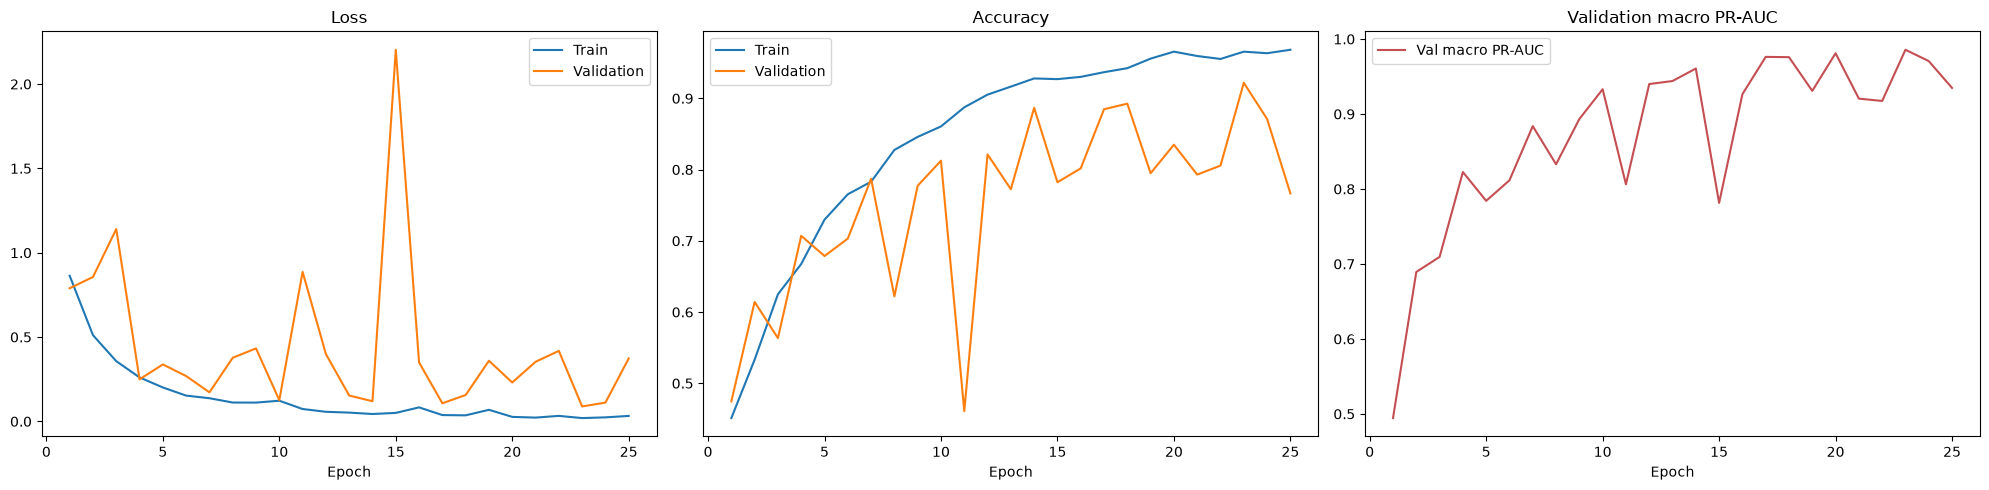

In [13]:
epochs_ran = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].plot(epochs_ran, history["train_loss"], label="Train")
axes[0].plot(epochs_ran, history["val_loss"], label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(epochs_ran, history["train_acc"], label="Train")
axes[1].plot(epochs_ran, history["val_acc"], label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()

axes[2].plot(epochs_ran, history["val_pr_auc"], color="#c44e52", label="Val macro PR-AUC")
axes[2].set_title("Validation macro PR-AUC"); axes[2].set_xlabel("Epoch"); axes[2].legend()

plt.tight_layout()
plt.show()

## Avaliação de Desempenho no Conjunto de Teste

O modelo é agora avaliado na **partição de teste reservada** (as 1.280 imagens
originais, nunca vistas durante treino/validação/seleção do modelo).

A métrica principal do projeto é a **área sob a curva Precisão-Revocação
(PR-AUC)**, escolha apropriada para classificação desbalanceada: ao contrário da
acurácia ou da ROC-AUC, a curva PR foca na classe positiva (minoritária) e não é
inflada pela abundância de verdadeiros negativos. Reportamo-la por classe e como
médias **macro** (média não ponderada, que trata todas as classes igualmente, a
visão mais rigorosa sob desbalanceamento) e **ponderada**.

Complementamos com um relatório de classificação completo, uma matriz de confusão
normalizada, ROC-AUC e acurácia balanceada / MCC, para um panorama clínico
abrangente.


In [14]:
# get probabilities and predictions on the test set
test_loss, test_acc, test_macro_pr_auc, y_true, y_prob = evaluate(
    model, test_loader, criterion, device
)
y_pred = y_prob.argmax(axis=1)
y_true_onehot = np.eye(NUM_CLASSES)[y_true]

ordered_class_names = [class_names[i] for i in range(NUM_CLASSES)]

print(f"Test loss            : {test_loss:.4f}")
print(f"Test accuracy        : {test_acc:.4f}")
print(f"Test macro PR-AUC    : {test_macro_pr_auc:.4f}")

Test loss            : 0.1309
Test accuracy        : 0.9023
Test macro PR-AUC    : 0.9780


Classification report:

                    precision    recall  f1-score   support

     Mild Demented     0.9930    0.8198    0.8981       172
 Moderate Demented     0.5769    1.0000    0.7317        15
      Non Demented     0.9720    0.8754    0.9212       634
Very Mild Demented     0.8207    0.9673    0.8880       459

          accuracy                         0.9023      1280
         macro avg     0.8406    0.9156    0.8597      1280
      weighted avg     0.9159    0.9023    0.9039      1280

Per-class sensitivity (recall) - the key clinical metric:
  Mild Demented       : 0.8198
  Moderate Demented   : 1.0000
  Non Demented        : 0.8754
  Very Mild Demented  : 0.9673


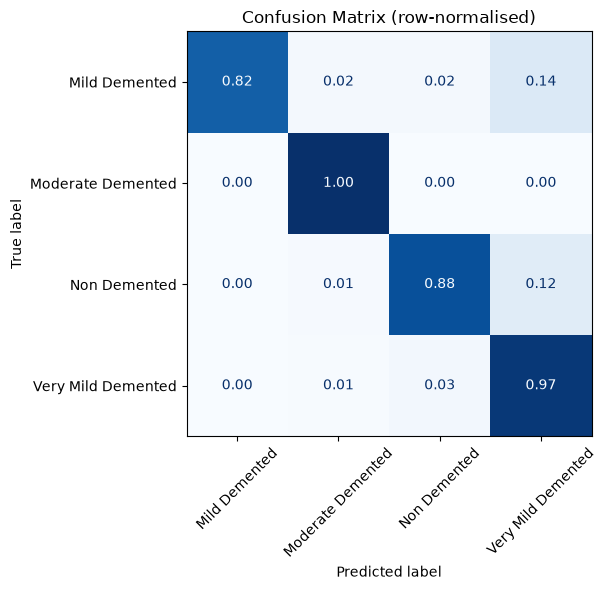

In [15]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, recall_score)

print("Classification report:\n")
print(classification_report(y_true, y_pred, target_names=ordered_class_names, digits=4))

rec = recall_score(y_true, y_pred, average=None)
print("Per-class sensitivity (recall) - the key clinical metric:")
for name, r in zip(ordered_class_names, rec):
    print(f"  {name:<20}: {r:.4f}")

# normalised confusion matrix (row = true class) highlights per-class recall
cm = confusion_matrix(y_true, y_pred, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=ordered_class_names).plot(
    ax=ax, cmap="Blues", values_format=".2f", xticks_rotation=45, colorbar=False
)
ax.set_title("Confusion Matrix (row-normalised)")
plt.tight_layout()
plt.show()


### Curvas Precisão-Revocação e PR-AUC (métrica principal)

Calculamos a curva PR de cada classe em um esquema Um-contra-Resto (One-vs-Rest)
e reportamos a Precisão Média (AP = área sob a curva PR). As linhas tracejadas
mostram a AP *de base* de cada classe (sua prevalência), isto é, a pontuação que
um classificador sem habilidade obteria, útil para avaliar o ganho real nas
classes mais raras.


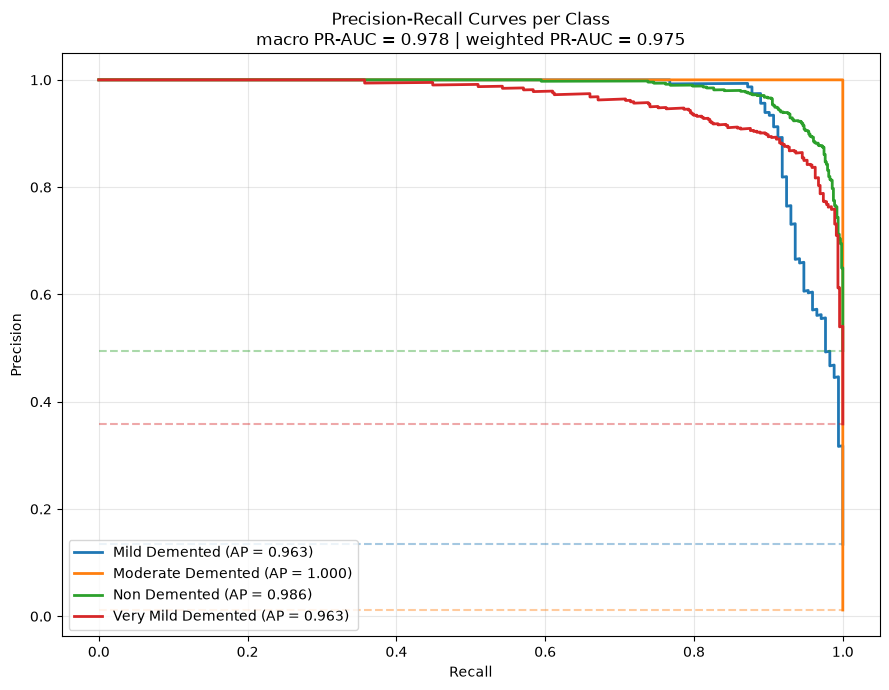

Average Precision (PR-AUC) per class:
  Mild Demented       : 0.9635
  Moderate Demented   : 1.0000
  Non Demented        : 0.9855
  Very Mild Demented  : 0.9632

Macro PR-AUC    : 0.9780
Weighted PR-AUC : 0.9747


In [16]:
from sklearn.metrics import precision_recall_curve

ap_per_class = {}
plt.figure(figsize=(9, 7))
palette = sns.color_palette("tab10", NUM_CLASSES)

for c in range(NUM_CLASSES):
    precision, recall, _ = precision_recall_curve(y_true_onehot[:, c], y_prob[:, c])
    ap = average_precision_score(y_true_onehot[:, c], y_prob[:, c])
    ap_per_class[ordered_class_names[c]] = ap
    plt.plot(recall, precision, color=palette[c], lw=2,
             label=f"{ordered_class_names[c]} (AP = {ap:.3f})")
    # no-skill baseline = class prevalence
    baseline = y_true_onehot[:, c].mean()
    plt.hlines(baseline, 0, 1, color=palette[c], linestyle="--", alpha=0.4)

macro_ap = average_precision_score(y_true_onehot, y_prob, average="macro")
weighted_ap = average_precision_score(y_true_onehot, y_prob, average="weighted")

plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"Precision-Recall Curves per Class\n"
          f"macro PR-AUC = {macro_ap:.3f} | weighted PR-AUC = {weighted_ap:.3f}")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Average Precision (PR-AUC) per class:")
for name, ap in ap_per_class.items():
    print(f"  {name:<20}: {ap:.4f}")
print(f"\nMacro PR-AUC    : {macro_ap:.4f}")
print(f"Weighted PR-AUC : {weighted_ap:.4f}")

### Métricas Complementares

Para uma avaliação completa e profissional, reportamos adicionalmente:

* **Acurácia balanceada:** média da revocação por classe, imune ao
  desbalanceamento.
* **Coeficiente de Correlação de Matthews (MCC)** e **κ de Cohen:** medidas
  robustas de concordância que levam o acaso em conta.
* **ROC-AUC macro (OvR):** reportada ao lado da PR-AUC por completude, observando
  que a PR-AUC continua sendo a métrica mais fiel sob forte desbalanceamento.


In [17]:
from sklearn.metrics import (balanced_accuracy_score, matthews_corrcoef,
                             cohen_kappa_score, roc_auc_score, f1_score)

macro_roc_auc = roc_auc_score(y_true_onehot, y_prob, average="macro", multi_class="ovr")

summary = {
    "Accuracy":            test_acc,
    "Balanced accuracy":   balanced_accuracy_score(y_true, y_pred),
    "Macro F1":            f1_score(y_true, y_pred, average="macro"),
    "Weighted F1":         f1_score(y_true, y_pred, average="weighted"),
    "Macro PR-AUC":        macro_ap,
    "Weighted PR-AUC":     weighted_ap,
    "Macro ROC-AUC (OvR)": macro_roc_auc,
    "MCC":                 matthews_corrcoef(y_true, y_pred),
    "Cohen's kappa":       cohen_kappa_score(y_true, y_pred),
}

summary_df = pd.DataFrame.from_dict(summary, orient="index", columns=["Score"])
summary_df["Score"] = summary_df["Score"].round(4)
print("==== Test-set performance summary ====")
print(summary_df.to_string())

==== Test-set performance summary ====
                      Score
Accuracy             0.9023
Balanced accuracy    0.9156
Macro F1             0.8597
Weighted F1          0.9039
Macro PR-AUC         0.9780
Weighted PR-AUC      0.9747
Macro ROC-AUC (OvR)  0.9882
MCC                  0.8455
Cohen's kappa        0.8405


### Explicabilidade: Grad-CAM

Um modelo clínico não pode ser uma caixa-preta. O **Grad-CAM** destaca as regiões
da imagem que mais influenciaram cada predição, sobrepondo um mapa de calor à RM
original. Isso nos permite verificar se a rede atenta para anatomia plausível
(hipocampo, ventrículos, córtex temporal) em vez de artefatos de aquisição.


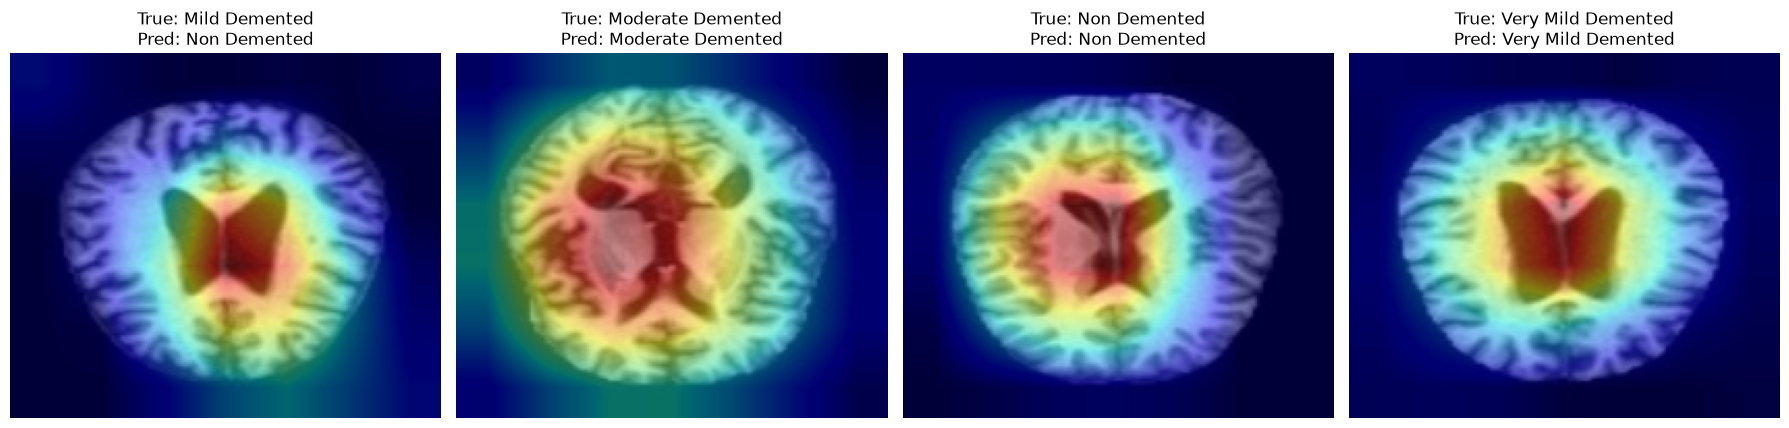

In [18]:
# Grad-CAM on the last residual block of the ResNet (model.layer4)
activations, gradients = {}, {}
def _fwd(m, i, o): activations["v"] = o.detach()
def _bwd(m, gi, go): gradients["v"] = go[0].detach()

target_layer = model.layer4[-1]
h1 = target_layer.register_forward_hook(_fwd)
h2 = target_layer.register_full_backward_hook(_bwd)

def gradcam(x):                                   # x: [1, 1, H, W] on device
    model.zero_grad()
    logits = model(x)
    cls = int(logits.argmax(1))
    logits[0, cls].backward()
    act = activations["v"][0]
    grad = gradients["v"][0]
    weights = grad.mean(dim=(1, 2))
    cam = F.relu((weights[:, None, None] * act).sum(0))
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)
    cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    return cam.cpu().numpy(), cls

# one example per class from the test set
examples = {}
for i in range(len(final_dataset["test"])):
    lbl = final_dataset["test"][i]["label"]
    examples.setdefault(lbl, i)
    if len(examples) == NUM_CLASSES:
        break

fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(18, 5))
for ax, (lbl, idx) in zip(axes, sorted(examples.items())):
    img = final_dataset["test"][idx]["pixel_values"].to(device)
    cam, pred = gradcam(img.unsqueeze(0))
    disp = (img[0].cpu().numpy() * 0.5) + 0.5          # un-normalise for display
    ax.imshow(disp, cmap="gray")
    ax.imshow(cam, cmap="jet", alpha=0.45)
    ax.set_title(f"True: {class_names[lbl]}\nPred: {class_names[pred]}")
    ax.axis("off")
plt.tight_layout(); plt.show()
h1.remove(); h2.remove()

### Calibração de Probabilidades: Temperature Scaling

Os escores do softmax costumam ser excessivamente confiantes. O **temperature
scaling** ajusta um único escalar `T` no conjunto de validação (minimizando a
NLL) que reescala os logits para que as probabilidades previstas correspondam às
frequências observadas. Reportamos o **Erro de Calibração Esperado (ECE)** antes e
depois, além de um diagrama de confiabilidade. Probabilidades calibradas são
essenciais para apoio à decisão clínica.


Optimal temperature: 0.770
ECE before calibration: 0.0426
ECE after  calibration: 0.0092


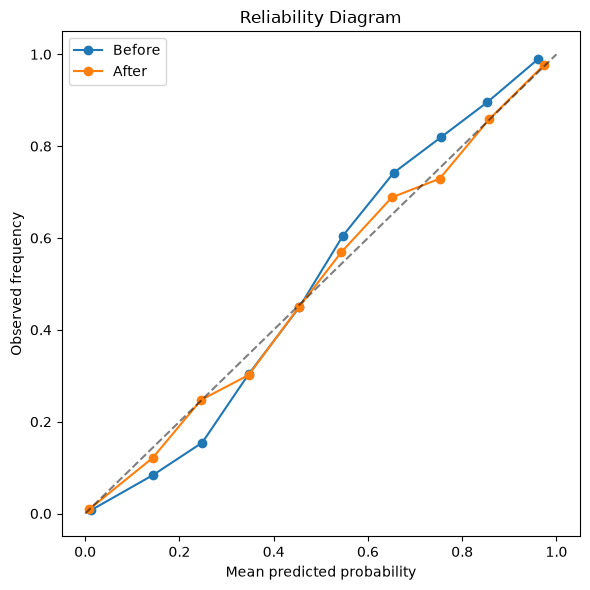

In [19]:
def get_logits(model, loader):
    model.eval()
    L, Y = [], []
    with torch.no_grad():
        for xb, yb in loader:
            L.append(model(xb.to(device)).cpu())
            Y.append(yb)
    return torch.cat(L), torch.cat(Y)

val_logits, val_y = get_logits(model, val_loader)
test_logits, test_y = get_logits(model, test_loader)

# fit a single temperature on the validation set
temperature = torch.ones(1, requires_grad=True)
opt = torch.optim.LBFGS([temperature], lr=0.01, max_iter=100)
nll = nn.CrossEntropyLoss()
def _closure():
    opt.zero_grad()
    loss = nll(val_logits / temperature, val_y)
    loss.backward()
    return loss
opt.step(_closure)
T_opt = temperature.item()
print(f"Optimal temperature: {T_opt:.3f}")

def ece(probs, labels, n_bins=10):
    conf, pred = probs.max(1)
    acc = (pred == labels).float()
    bins = torch.linspace(0, 1, n_bins + 1)
    e = 0.0
    for b in range(n_bins):
        m = (conf > bins[b]) & (conf <= bins[b + 1])
        if m.sum() > 0:
            e += (m.float().mean() * (acc[m].mean() - conf[m].mean()).abs()).item()
    return e

p_before = F.softmax(test_logits, dim=1)
p_after = F.softmax(test_logits / T_opt, dim=1)
print(f"ECE before calibration: {ece(p_before, test_y):.4f}")
print(f"ECE after  calibration: {ece(p_after, test_y):.4f}")

from sklearn.calibration import calibration_curve
yb_oh = np.eye(NUM_CLASSES)[test_y.numpy()]
fig, ax = plt.subplots(figsize=(6, 6))
for probs, lab in [(p_before.numpy(), "Before"), (p_after.numpy(), "After")]:
    fr, mp = calibration_curve(yb_oh.ravel(), probs.ravel(), n_bins=10)
    ax.plot(mp, fr, marker="o", label=lab)
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed frequency")
ax.set_title("Reliability Diagram"); ax.legend()
plt.tight_layout(); plt.show()

### Limiares de Decisão Clínica

A decisão padrão por `argmax` não é ótima em rastreamento. No estadiamento do
Alzheimer, um **falso negativo** (deixar passar um caso real) é mais custoso do
que um falso positivo (solicitar um exame adicional). Usando a curva PR de
validação, escolhemos, por classe, o limiar de operação que atinge uma
**sensibilidade-alvo (>= 95%)** e reportamos a precisão resultante no conjunto de
teste (um-contra-resto, sobre probabilidades calibradas).


In [20]:
from sklearn.metrics import precision_recall_curve

TARGET_SENS = 0.95
val_probs = F.softmax(val_logits, dim=1).numpy()
test_probs = p_after.numpy()                      # calibrated
val_oh = np.eye(NUM_CLASSES)[val_y.numpy()]

rows = []
for c in range(NUM_CLASSES):
    prec, rec_c, thr = precision_recall_curve(val_oh[:, c], val_probs[:, c])
    ok = np.where(rec_c[:-1] >= TARGET_SENS)[0]
    t = thr[ok[-1]] if len(ok) else 0.0
    pred_c = (test_probs[:, c] >= t).astype(int)
    true_c = (test_y.numpy() == c).astype(int)
    tp = int(((pred_c == 1) & (true_c == 1)).sum())
    fn = int(((pred_c == 0) & (true_c == 1)).sum())
    fp = int(((pred_c == 1) & (true_c == 0)).sum())
    sens = tp / (tp + fn + 1e-9)
    prec_op = tp / (tp + fp + 1e-9)
    rows.append([ordered_class_names[c], round(float(t), 3), round(sens, 3), round(prec_op, 3)])

print(f"Per-class operating points for >= {TARGET_SENS:.0%} sensitivity (calibrated, OvR):\n")
print(pd.DataFrame(rows, columns=["Class", "Threshold", "Test sensitivity", "Test precision"]).to_string(index=False))

Per-class operating points for >= 95% sensitivity (calibrated, OvR):

             Class  Threshold  Test sensitivity  Test precision
     Mild Demented      0.105             0.907           0.918
 Moderate Demented      0.996             1.000           1.000
      Non Demented      0.290             0.918           0.940
Very Mild Demented      0.604             0.950           0.857


### Incerteza Preditiva: MC-Dropout

Manter o dropout ativo na inferência e executar várias passagens estocásticas
diretas aproxima uma posterior bayesiana. A **entropia preditiva** das
probabilidades médias quantifica o quanto o modelo está inseguro. Casos acima de
um limiar de alta incerteza podem ser **sinalizados para revisão humana**, a
postura de humano-no-circuito (human-in-the-loop) esperada de uma ferramenta de
apoio à decisão clínica.


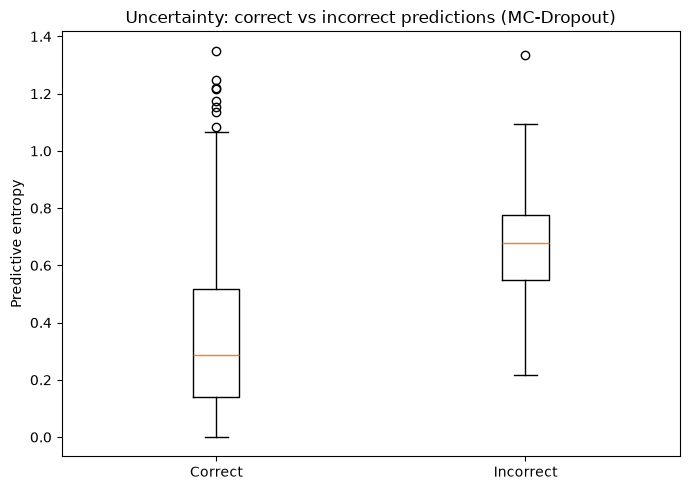

Mean entropy | correct: 0.344 | incorrect: 0.673
Cases flagged for human review (top 10% uncertainty): 128 / 1280
Accuracy on confident 90%: 0.930 | on flagged 10%: 0.656


ResNet(
  (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [21]:
def enable_dropout(model):
    for m in model.modules():
        if isinstance(m, nn.Dropout):
            m.train()

MC_PASSES = 30
model.eval()
enable_dropout(model)

mc = []
with torch.no_grad():
    for _ in range(MC_PASSES):
        batch_probs = [F.softmax(model(xb.to(device)), dim=1).cpu().numpy() for xb, _ in test_loader]
        mc.append(np.concatenate(batch_probs))
mc = np.stack(mc)                                   # [passes, N, C]
mean_prob = mc.mean(0)
pred_mc = mean_prob.argmax(1)
entropy = -(mean_prob * np.log(mean_prob + 1e-9)).sum(1)
correct = pred_mc == y_true

fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot([entropy[correct], entropy[~correct]], tick_labels=["Correct", "Incorrect"])
ax.set_ylabel("Predictive entropy")
ax.set_title("Uncertainty: correct vs incorrect predictions (MC-Dropout)")
plt.tight_layout(); plt.show()

flag = entropy > np.quantile(entropy, 0.90)
print(f"Mean entropy | correct: {entropy[correct].mean():.3f} | incorrect: {entropy[~correct].mean():.3f}")
print(f"Cases flagged for human review (top 10% uncertainty): {int(flag.sum())} / {len(flag)}")
print(f"Accuracy on confident 90%: {correct[~flag].mean():.3f} | on flagged 10%: {correct[flag].mean():.3f}")
model.eval()

### Validação Cruzada Estratificada k-fold (opcional)

Uma única divisão fornece uma estimativa de alta variância, especialmente para a
rara classe Moderada. A **validação cruzada estratificada de 5 folds** retreina o
modelo em cada fold e reporta a média +/- desvio-padrão da PR-AUC macro. Ela fica
condicionada à flag `RUN_KFOLD`, pois custa cerca de 5x o tempo de treinamento.


In [22]:
from sklearn.model_selection import StratifiedKFold

RUN_KFOLD = False        # set True to run 5-fold CV (~5x training time)
N_FOLDS = 5
KFOLD_EPOCHS = 12

if RUN_KFOLD:
    base = dataset["train"]
    all_labels = np.array(base["label"])
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    fold_scores = []
    for fold, (tr_idx, va_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels), 1):
        tr_set = base.select(tr_idx.tolist()); tr_set.set_transform(apply_transformations)
        va_set = base.select(va_idx.tolist()); va_set.set_transform(apply_transformations)
        tr_loader = DataLoader(AugmentedDataset(tr_set, train_augment), batch_size=BATCH_SIZE,
                               shuffle=True, collate_fn=collate_fn, num_workers=0)
        va_loader = DataLoader(va_set, batch_size=BATCH_SIZE, shuffle=False,
                               collate_fn=collate_fn, num_workers=0)
        net = build_resnet18_1ch(NUM_CLASSES, pretrained=True).to(device)
        opt = torch.optim.AdamW(net.parameters(), lr=3e-4, weight_decay=1e-4)
        crit = FocalLoss(alpha=class_weights, gamma=2.0)
        best = -np.inf
        for _ in range(KFOLD_EPOCHS):
            net.train()
            for xb, yb in tr_loader:
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad(); loss = crit(net(xb), yb); loss.backward()
                torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
            _, _, pa, _, _ = evaluate(net, va_loader, crit, device)
            best = max(best, pa)
        fold_scores.append(best)
        print(f"Fold {fold}: best val macro PR-AUC = {best:.4f}")
    print(f"\n5-fold macro PR-AUC: {np.mean(fold_scores):.4f} +/- {np.std(fold_scores):.4f}")
else:
    print("K-fold cross-validation is disabled (set RUN_KFOLD = True to run it).")

K-fold cross-validation is disabled (set RUN_KFOLD = True to run it).


### Fusão Multimodal e 3D: Trabalhos Futuros

As duas extensões clínicas de maior impacto não podem ser treinadas com este
conjunto de dados (o `Falah/Alzheimer_MRI` fornece apenas `image` + `label`), por
isso são documentadas aqui com um projeto concreto.

**Fusão multimodal.** O diagnóstico real de Alzheimer combina a RM com **escore
MMSE, idade, sexo, genótipo APOE, PET de amiloide e biomarcadores do líquor**. O
esqueleto abaixo mostra como tais atributos tabulares seriam concatenados às
características de imagem após o pooling global e passados por uma cabeça conjunta.
Com o conjunto ADNI (que fornece esses metadados), o modelo seria diretamente
treinável.

**Modelagem volumétrica 3D.** Fatias 2D descartam a atrofia volumétrica do
hipocampo, que é o biomarcador mais consistente da DA. Uma **CNN 3D** ou um
backbone pré-treinado como o **MedicalNet (ResNet 3D)** sobre volumes completos de
RM capturaria essa informação; isso requer os volumes NIfTI originais, e não os
PNGs já fatiados usados aqui.


In [23]:
# Architectural skeleton for a MULTIMODAL extension (illustrative, not trainable here because the dataset has no clinical metadata)
# Shows how tabular features (MMSE, age, sex, APOE, PET/CSF biomarkers) fuse with imaging features after GAP.
class MultimodalAlzheimerNet(nn.Module):
    def __init__(self, num_classes=4, n_tabular=8, dropout=0.5):
        super().__init__()
        backbone = build_resnet18_1ch(num_classes, dropout, pretrained=True)
        self.image_features = nn.Sequential(*list(backbone.children())[:-1])   # ResNet up to GAP -> [B,512,1,1]
        self.tabular_encoder = nn.Sequential(
            nn.Linear(n_tabular, 32), nn.ReLU(inplace=True),
            nn.Linear(32, 32), nn.ReLU(inplace=True),
        )
        self.head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(512 + 32, 128), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(128, num_classes),
        )
    def forward(self, image, tabular):
        f_img = self.image_features(image).flatten(1)
        f_tab = self.tabular_encoder(tabular)
        return self.head(torch.cat([f_img, f_tab], dim=1))

mm = MultimodalAlzheimerNet(NUM_CLASSES, n_tabular=8)
print("MultimodalAlzheimerNet defined (illustrative; requires clinical metadata, e.g. ADNI, to train).")
print(f"Parameter count: {sum(p.numel() for p in mm.parameters()):,}")

MultimodalAlzheimerNet defined (illustrative; requires clinical metadata, e.g. ADNI, to train).
Parameter count: 11,241,860


## Conclusão

Construímos um único pipeline com orientação clínica para classificar imagens de
RM cerebral nos quatro estágios de Alzheimer do conjunto Falah/Alzheimer_MRI:

1. A **AED** revelou um conjunto fortemente desbalanceado (Demência Moderada é ~50x mais rara do que Sem Demência).
2. O **pré-processamento** padronizou as imagens (redimensionamento, escala de cinza, normalização), e uma **augmentação geométrica moderada** foi aplicada apenas ao conjunto de treino.
3. Uma divisão **estratificada** em treino/validação/teste preservou as proporções das classes.
4. Uma **ResNet-18 pré-treinada na ImageNet** (adaptada para RM de 1 canal) foi ajustada com **Focal Loss** (pesos de classe inversos à frequência, sem reamostrador) e **recorte de gradiente**, com parada antecipada na PR-AUC macro de validação.
5. A **avaliação** centrou-se na **PR-AUC** (a métrica-alvo do projeto), complementada por matriz de confusão, acurácia balanceada, F1, MCC e ROC-AUC.
6. Uma **camada clínica** acrescentou explicabilidade com Grad-CAM, calibração de probabilidades (temperature scaling + ECE), limiares de decisão orientados à sensibilidade e incerteza por MC-Dropout com sinalização para revisão humana. A validação cruzada k-fold estratificada está disponível para estimativas mais robustas à variância.

**Limitações remanescentes**

| Limitação | Situação |
|---|---|
| Classe Moderada rara (~49 imgs) | Mitigada (Focal Loss), não resolvida: precisa de mais dados |
| Sem metadados clínicos (MMSE, idade, APOE) | Esqueleto fornecido; precisa de dados no estilo ADNI |
| Fatias 2D perdem a atrofia volumétrica | Documentado; precisa de volumes 3D (CNN 3D / MedicalNet) |

**Ressalva científica.** Sabe-se que este conjunto de dados contém imagens
aumentadas quase duplicadas e **não é separado por paciente**, de modo que alguns
escores reportados podem ser otimistas devido a possível vazamento de dados (a AP
perfeita na minúscula classe Moderada é um sinal claro). Qualquer afirmação
clínica exigiria validação em uma coorte disjunta por paciente, coletada de forma
prospectiva.
